<a href="https://colab.research.google.com/github/diosthenes/langevin-dynamics/blob/main/Langevin_Dynamics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import truncnorm

In [2]:
#Particle and Simulation Parameters
x = np.linspace(-10, 10, 1000)
n = 100
x_particles = np.full(n, 5) #initial particle position at x=5
t_start = 0
t_stop = 10000
dt = 0.001
n_steps = int((t_stop - t_start)/dt)

In [3]:
#Physical Parameters
gamma = 1.0
kB = 1.0
k_potential = 1.0
a_temperature = 12.5
T_1 = 100
T_2 = 200
c_temperature = (T_1 + T_2)/2

In [4]:
#Potential
def potential(x):
  V = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [lambda x: (x+5)**2, k_potential, lambda x: (x-5)**2])
  return V

In [5]:
#Temperature function
def Temperature(x):
  T = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [T_1, lambda x:(a_temperature * x) + c_temperature, T_2])
  return T

In [6]:
#External Force due to the potential
def dV_dx(x):
  F = np.piecewise(x, [x<-4, (-4<=x) & (x<=4), x>4], [lambda x: 2*(x+5), 0, lambda x: 2*(x-5)])
  return F

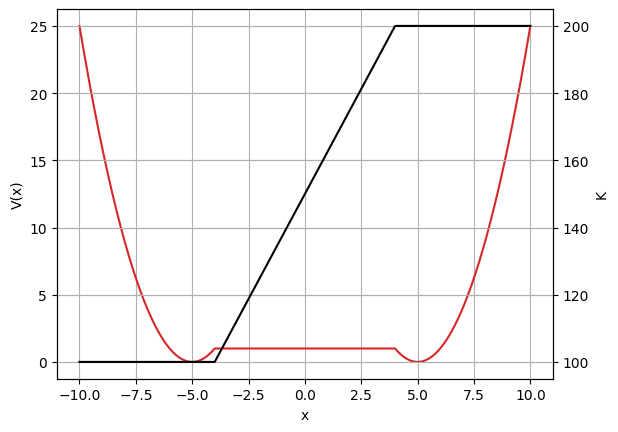

In [7]:
#Potential and Temperature Visualisation
fig, ax1 = plt.subplots()
#Potential
color = 'tab:red'
ax1.plot(x, potential(x), color=color, label='Potential')
ax1.set_xlabel('x')
ax1.set_ylabel('V(x)')
plt.grid()
#Temperature
ax2 = ax1.twinx()
color = 'black'
ax2.plot(x, Temperature(x), color=color, label='Temperature Function')
ax2.set_ylabel('K')
plt.grid()
plt.show()

In [8]:
#Euler-Maruyama Integration
for i in range(n_steps):
  T = Temperature(x_particles)
  noise_amp = np.sqrt((2*kB*T)/gamma)
  N_noise = np.random.randn(n)
  F_pot = (-1/gamma) * dV_dx(x_particles) * dt
  N_t = noise_amp * N_noise * np.sqrt(dt)

  x_particles = x_particles + F_pot + N_t

print(x_particles)

[-13.2191685   -4.56321502  20.88898957  -9.24062729 -21.59354006
 -17.69609392  -3.05963945  -3.1040561   -2.11926432  -5.81858929
  22.66966156   9.19155052  -1.48410204 -13.723421   -11.25330251
   2.49369295  -5.10942085  -6.38821757  10.66262318 -13.73267579
   5.13762753  22.10616337   0.27679435  -4.03762289   9.15307669
  -1.0054071   -1.22448193   8.56461809  -2.23963798  -6.24671285
   4.9572835   -5.51300647  -8.09711845  -1.47088029  -9.57284117
 -10.35898592   0.71064939  -4.45684413 -15.47114759  -1.02142661
  -7.97907702   1.65069005  -1.51331258  16.90713813 -18.35487123
  11.83058523  -2.64401661 -20.55564118   1.57644845  -7.39723073
  37.79855666  17.57952696  -2.69048338  16.62677236  17.39691093
 -13.25475942   6.18069703   0.46313262  -1.8162581  -17.21421162
  -3.15517302  -1.34333041  -9.70772264  -8.69304261  -8.70361308
 -15.52259805  -6.26436137  14.20972742   8.31970433  -8.84054451
   8.67203275  11.47011291  14.093122    19.617472     0.75118983
   8.35301

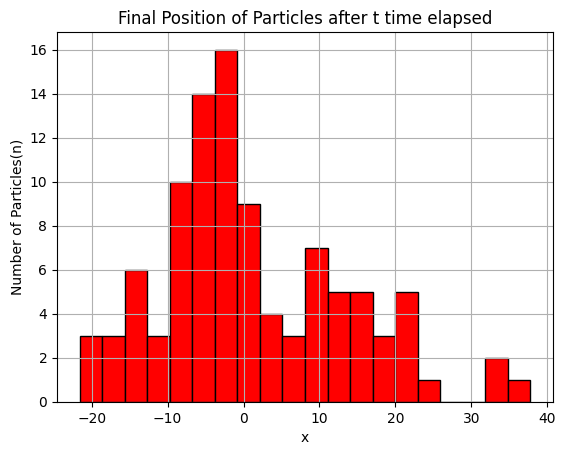

In [9]:
#Histogram of Final Particle Positions
plt.hist(x_particles, bins=20, color='red', edgecolor='black')
plt.title('Final Position of Particles after t time elapsed')
plt.xlabel('x')
plt.ylabel('Number of Particles(n)')
plt.grid()

In [11]:
#Check with equilibrium probability density result
D_inv = gamma/(kB * Temperature(x))
U = potential(x)
exp = U/(kB * Temperature(x))
def P(x):
  P = D_inv * np.exp(-exp)
  return P

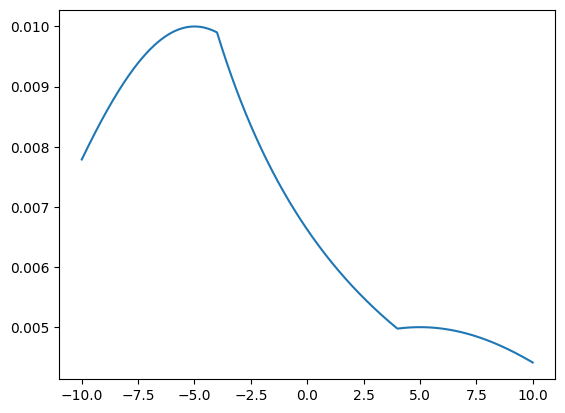

In [12]:
#Prob density plot
plt.plot(x, P(x))
plt.grid()